In [3]:
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense,Input
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report,confusion_matrix

In [5]:
train = pd.read_csv("sign_mnist_train.csv")
test = pd.read_csv("sign_mnist_test.csv")
print(train.shape)
print(test.shape)

(27455, 785)
(7172, 785)


In [11]:
x_train = train[train["label"]!=24].drop("label",axis=1)
x_test = test.drop("label",axis=1)
y_test = (test["label"]==24).astype(int)

In [12]:
x_train = x_train/255.0
x_test = x_test/255.0

In [15]:
model = Sequential([
    Input(shape=(784,)),
    Dense(128,activation="relu"),
    Dense(64,activation="relu"),
    Dense(32,activation="relu"),
    Dense(64,activation="relu"),
    Dense(128,activation="relu"),
    Dense(784,activation="sigmoid")
])
model.compile(optimizer="adam",loss="mse")
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_12 (Dense)                     │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_13 (Dense)                     │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_14 (Dense)                     │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_15 (Dense)                     │ (None, 64)                  │           2,112 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_16 (Dense)                     │ (None, 128)                 │           8,320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_17 (Dense)                     │ (None, 784)                 │         101,136 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 222,384 (868.69 KB)

 Trainable params: 222,384 (868.69 KB)

 Non-trainable params: 0 (0.00 B)

In [17]:
history = model.fit(
    x_train,x_train,
    epochs=20,
    validation_split=0.1,
    batch_size=128
)

Epoch 1/20
186/186 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - loss: 0.0262 - val_loss: 0.0195
Epoch 2/20
186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0153 - val_loss: 0.0135
Epoch 3/20
186/186 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.0124 - val_loss: 0.0121
Epoch 4/20
186/186 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 0.0113 - val_loss: 0.0111
Epoch 5/20
186/186 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.0107 - val_loss: 0.0107
Epoch 6/20
186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0101 - val_loss: 0.0100
Epoch 7/20
186/186 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.0097 - val_loss: 0.0095
Epoch 8/20
186/186 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.0093 - val_loss: 0.0092
Epoch 9/20
186/186 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.0091 - val_loss: 0.0090
Epoch 10/20
186/186 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.0089 - val_loss: 0.0089
Epoch 11/20
186/186 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.0086 - val_loss: 0.0087
Epoch 12/20
186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/ste

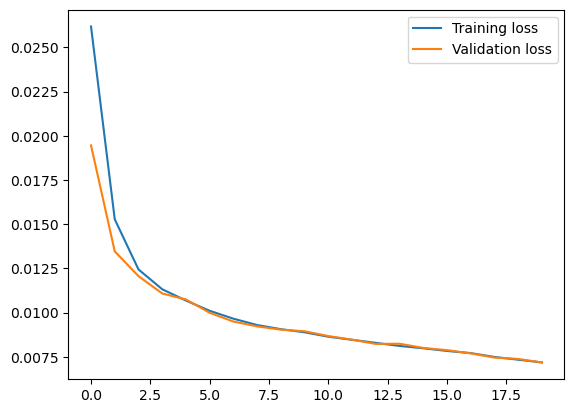

In [18]:
plt.plot(history.history["loss"],label="Training loss")
plt.plot(history.history["val_loss"],label="Validation loss")
plt.xlabel=("Epoch")
plt.ylabel=("Loss")
plt.legend()
plt.show()

In [19]:
train_pred = model.predict(x_train)
train_error = np.mean(np.square(train_pred - x_train),axis=1)
threshold = np.mean(train_error) + 3*np.std(train_error)
print("Threshold:",threshold)

824/824 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step
Threshold: 0.01642939073797478


In [23]:
test_pred = model.predict(x_test)
test_error = np.mean(np.square(test_pred-x_test),axis=1)
y_pred = (test_error>threshold).astype(int)
print("Detected Anomalies:",np.sum(y_pred))

225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step 
Detected Anomalies: 219


In [24]:
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Confusion Matrix:
[[6648  192]
 [ 305   27]]

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.97      0.96      6840
           1       0.12      0.08      0.10       332

    accuracy                           0.93      7172
   macro avg       0.54      0.53      0.53      7172
weighted avg       0.92      0.93      0.92      7172



In [ ]:
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense,Input
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report,confusion_matrix


train = pd.read_csv("sign_mnist_train.csv")
test = pd.read_csv("sign_mnist_test.csv")
print(train.shape)
print(test.shape)


x_train = train[train["label"]!=24].drop("label",axis=1)
x_test = test.drop("label",axis=1)
y_test = (test["label"]==24).astype(int)
x_train = x_train/255.0
x_test = x_test/255.0


model = Sequential([
    Input(shape=(784,)),
    Dense(128,activation="relu"),
    Dense(64,activation="relu"),
    Dense(32,activation="relu"),
    Dense(64,activation="relu"),
    Dense(128,activation="relu"),
    Dense(784,activation="sigmoid")
])
model.compile(optimizer="adam",loss="mse")
model.summary()


history = model.fit(
    x_train,x_train,
    epochs=20,
    validation_split=0.1,
    batch_size=128
)


plt.plot(history.history["loss"],label="Training loss")
plt.plot(history.history["val_loss"],label="Validation loss")
plt.xlabel=("Epoch")
plt.ylabel=("Loss")
plt.legend()
plt.show()


train_pred = model.predict(x_train)
train_error = np.mean(np.square(train_pred - x_train),axis=1)
threshold = np.mean(train_error) + 3*np.std(train_error)
print("Threshold:",threshold)

test_pred = model.predict(x_test)
test_error = np.mean(np.square(test_pred-x_test),axis=1)
y_pred = (test_error>threshold).astype(int)
print("Detected Anomalies:",np.sum(y_pred))


print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))
